Connecting Our Project tot the Drive

In [1]:

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np

DATA_DIR = "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection"
TRAIN_FILE = os.path.join(DATA_DIR, "train_transaction.csv")

if os.path.exists(TRAIN_FILE):
    print("Dataset found successfully!")
    print("Training file:", TRAIN_FILE)
else:
    print("Training file not found. Please check the folder path.")


Mounted at /content/drive
Dataset found successfully!
Training file: /content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection/train_transaction.csv


The Following code will Install and check the required libraries

In [2]:

# Install the libraries needed for our experiments
%pip install -q lightgbm imbalanced-learn

# Import and check versions
import pandas as pd
import numpy as np
import sklearn
import lightgbm as lgb
import imblearn
import matplotlib.pyplot as plt

print("Environment ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("LightGBM:", lgb.__version__)
print("Imbalanced-learn:", imblearn.__version__)


Environment ready!
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
LightGBM: 4.6.0
Imbalanced-learn: 0.14.2


Load the training dataset

In [3]:

# Load the training dataset
df = pd.read_csv(TRAIN_FILE)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Separate target from input features
target = "isFraud"

y = df[target].copy()

# Exclude target and transaction identifier from model features
X = df.drop(columns=["isFraud", "TransactionID"])

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFraud distribution:")
print(y.value_counts().rename(index={0: "Non-fraud", 1: "Fraud"}))

print("\nFraud percentage:", round(y.mean() * 100, 3), "%")
print("\nDataset memory usage:", round(df.memory_usage(deep=True).sum() / (1024**3), 2), "GB")


Dataset loaded successfully!
Dataset shape: (590540, 394)

Feature matrix shape: (590540, 392)
Target shape: (590540,)

Fraud distribution:
isFraud
Non-fraud    569877
Fraud         20663
Name: count, dtype: int64

Fraud percentage: 3.499 %

Dataset memory usage: 2.01 GB


Preparing the features for LightGBM

In [4]:

# Identify categorical and numerical features
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Number of features:", X.shape[1])
print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numeric_cols))

print("\nCategorical columns:")
print(categorical_cols)

print("\nTransactionDT included:", "TransactionDT" in X.columns)
print("TransactionID excluded:", "TransactionID" not in X.columns)
print("Target excluded:", "isFraud" not in X.columns)

# Check missing values in the categorical features
print("\nMissing values in categorical features:")
print(X[categorical_cols].isna().sum().sort_values(ascending=False))


Number of features: 392
Categorical features: 14
Numerical features: 378

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']

TransactionDT included: True
TransactionID excluded: True
Target excluded: True

Missing values in categorical features:
R_emaildomain    453249
M5               350482
M7               346265
M8               346252
M9               346252
M4               281444
M1               271100
M3               271100
M2               271100
M6               169360
P_emaildomain     94456
card4              1577
card6              1571
ProductCD             0
dtype: int64


Creating the chronological train/test split

In [5]:

# Chronological 70/30 split
# Keep the original dataset order unchanged
time_order = np.argsort(df["TransactionDT"].to_numpy(), kind="stable")

split_index = int(len(df) * 0.70)

train_idx = time_order[:split_index]
test_idx = time_order[split_index:]

X_train_time = X.iloc[train_idx]
X_test_time = X.iloc[test_idx]

y_train_time = y.iloc[train_idx]
y_test_time = y.iloc[test_idx]

print("Chronological split completed!")
print("\nTraining rows:", f"{len(train_idx):,}")
print("Testing rows:", f"{len(test_idx):,}")

print("\nTraining time range:")
print(
    df["TransactionDT"].iloc[train_idx].min(),
    "to",
    df["TransactionDT"].iloc[train_idx].max()
)

print("\nTesting time range:")
print(
    df["TransactionDT"].iloc[test_idx].min(),
    "to",
    df["TransactionDT"].iloc[test_idx].max()
)

print("\nTraining fraud rate:", round(y_train_time.mean() * 100, 3), "%")
print("Testing fraud rate:", round(y_test_time.mean() * 100, 3), "%")

assert (
    df["TransactionDT"].iloc[train_idx].max()
    <= df["TransactionDT"].iloc[test_idx].min()
), "Warning: the chronological split is not properly ordered!"


Chronological split completed!

Training rows: 413,378
Testing rows: 177,162

Training time range:
86400 to 10437996

Testing time range:
10438003 to 15811131

Training fraud rate: 3.517 %
Testing fraud rate: 3.457 %


Traning the base line model

In [6]:

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    matthews_corrcoef,
    classification_report
)
import lightgbm as lgb
import numpy as np
import pandas as pd

# Prepare copies for LightGBM categorical handling
X_train = X_train_time.copy()
X_test = X_test_time.copy()

# Convert categorical columns consistently
for col in categorical_cols:
    X_train[col] = X_train[col].astype("category")
    X_test[col] = pd.Categorical(
        X_test[col],
        categories=X_train[col].cat.categories
    )

# Train the unweighted baseline **
baseline_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

baseline_model.fit(
    X_train,
    y_train_time,
    categorical_feature=categorical_cols
)

# Predict fraud probabilities and labels
y_prob = baseline_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

# Evaluate
baseline_results = {
    "PR-AUC (Average Precision)": average_precision_score(y_test_time, y_prob),
    "Precision": precision_score(y_test_time, y_pred, zero_division=0),
    "Recall": recall_score(y_test_time, y_pred, zero_division=0),
    "F1": f1_score(y_test_time, y_pred, zero_division=0),
    "F2": fbeta_score(y_test_time, y_pred, beta=2, zero_division=0),
    "MCC": matthews_corrcoef(y_test_time, y_pred)
}

print("CHRONOLOGICAL BASELINE RESULTS")
print("-" * 40)

for metric, value in baseline_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_time,
    y_pred,
    target_names=["Non-fraud", "Fraud"],
    zero_division=0
))


CHRONOLOGICAL BASELINE RESULTS
----------------------------------------
PR-AUC (Average Precision): 0.5239
Precision: 0.7549
Recall: 0.3435
F1: 0.4722
F2: 0.3855
MCC: 0.4985

Classification report:
              precision    recall  f1-score   support

   Non-fraud       0.98      1.00      0.99    171037
       Fraud       0.75      0.34      0.47      6125

    accuracy                           0.97    177162
   macro avg       0.87      0.67      0.73    177162
weighted avg       0.97      0.97      0.97    177162



Code for saving the frist baseline result

In [7]:

# Save baseline metrics to Google Drive
baseline_df = pd.DataFrame([
    {
        "Evaluation": "Chronological 70/30",
        "Model": "LightGBM baseline",
        **baseline_results
    }
])

results_path = os.path.join(DATA_DIR, "fraud_model_results.csv")
baseline_df.to_csv(results_path, index=False)

print("Baseline results saved successfully!")
print(results_path)
display(baseline_df.round(4))


Baseline results saved successfully!
/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection/fraud_model_results.csv


,Evaluation,Model,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,Chronological 70/30,LightGBM baseline,0.5239,0.7549,0.3435,0.4722,0.3855,0.4985


Train the class-weighted mode

In [9]:

# Model 2: Class-weighted LightGBM

weighted_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",#**
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train only on the chronological training set
weighted_model.fit(
    X_train,
    y_train_time,
    categorical_feature=categorical_cols
)

# Predict on the same untouched chronological test set
weighted_prob = weighted_model.predict_proba(X_test)[:, 1]
weighted_pred = (weighted_prob >= 0.5).astype(int)

# Evaluate using the same metrics as the baseline
weighted_results = {
    "PR-AUC (Average Precision)": average_precision_score(
        y_test_time, weighted_prob
    ),
    "Precision": precision_score(
        y_test_time, weighted_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test_time, weighted_pred, zero_division=0
    ),
    "F1": f1_score(y_test_time, weighted_pred, zero_division=0),
    "F2": fbeta_score(
        y_test_time, weighted_pred, beta=2, zero_division=0
    ),
    "MCC": matthews_corrcoef(y_test_time, weighted_pred)
}

print("CHRONOLOGICAL CLASS-WEIGHTED RESULTS")
print("-" * 45)

for metric, value in weighted_results.items():
    print(f"{metric}: {value:.4f}")


CHRONOLOGICAL CLASS-WEIGHTED RESULTS
---------------------------------------------
PR-AUC (Average Precision): 0.5279
Precision: 0.2784
Recall: 0.6612
F1: 0.3918
F2: 0.5186
MCC: 0.3992


Prepare the SMOTE experiment

In [2]:

import os
import pandas as pd

DATA_DIR = "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection"
results_path = os.path.join(DATA_DIR, "fraud_model_results.csv")

# Load saved results into memory
if not os.path.exists(results_path):
    raise FileNotFoundError(
        f"Results file not found: {results_path}"
    )

results = pd.read_csv(results_path)

# Recover the class-weighted model metrics
weighted_row = results.loc[
    results["Model"] == "LightGBM class-weighted"
]

if weighted_row.empty:
    raise ValueError(
        "The class-weighted model was not found in the saved results."
    )

metric_names = [
    "PR-AUC (Average Precision)",
    "Precision",
    "Recall",
    "F1",
    "F2",
    "MCC"
]

weighted_results = {
    metric: float(weighted_row.iloc[0][metric])
    for metric in metric_names
}

print("Saved results loaded successfully.")
display(results)

print("\nClass-weighted metrics recovered:")
print(weighted_results)


Saved results loaded successfully.


,Evaluation,Model,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,Chronological 70/30,LightGBM baseline,0.523940,0.754934,0.343510,0.472172,0.385532,0.498481
1,Chronological 70/30,LightGBM class-weighted,0.527906,0.278389,0.661224,0.391815,0.518593,0.399169



Class-weighted metrics recovered:
{'PR-AUC (Average Precision)': 0.5279057029343901, 'Precision': 0.2783887819631565, 'Recall': 0.6612244897959184, 'F1': 0.391815411406182, 'F2': 0.5185925015365703, 'MCC': 0.3991693672834883}


In [3]:

import os
import gc
import pandas as pd
import numpy as np

DATA_DIR = "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection"
TRAIN_FILE = os.path.join(DATA_DIR, "train_transaction.csv")

# Load only the target and transaction time first
meta = pd.read_csv(
    TRAIN_FILE,
    usecols=["isFraud", "TransactionDT"]
)

# Recreate the chronological 70/30 split
time_order = np.argsort(
    meta["TransactionDT"].to_numpy(),
    kind="stable"
)
split_index = int(len(meta) * 0.70)

train_idx = time_order[:split_index]
test_idx = time_order[split_index:]

y_train_time = meta["isFraud"].iloc[train_idx].reset_index(drop=True)
y_test_time = meta["isFraud"].iloc[test_idx].reset_index(drop=True)

print("Chronological split recovered.")
print("Training rows:", len(train_idx))
print("Testing rows:", len(test_idx))
print("Training fraud rate:", f"{y_train_time.mean() * 100:.3f}%")
print("Testing fraud rate:", f"{y_test_time.mean() * 100:.3f}%")

del meta, time_order
gc.collect()


Chronological split recovered.
Training rows: 413378
Testing rows: 177162
Training fraud rate: 3.517%
Testing fraud rate: 3.457%


0

In [4]:

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os

print("\nTop-level folders in MyDrive:")
print(os.listdir('/content/drive/MyDrive')[:50])


Mounted at /content/drive

Top-level folders in MyDrive:
['Getting started.pdf', 'New Document_jpg.zip', 'IMG-20201009-WA0028.jpg', '20201127_120856.jpg', 'Screenshot_20220405-091110.jpg', '2024142262.pdf', 'KARTHIK INCOME CERTIFICATE.pdf', 'Fee structure 2024-25 - 15.02.2024 (4).pdf', 'Convert_ENVIRONMENT OF THE EARTH km8956.pdf', '01. UNIT 1_copy.pdf', 'ct of tcs.jpg', 'OD332299149603611100.pdf', 'steam analysis pps assignment .pdf', 'Coding Challenges - SRM Coding Bootcamp.pdf', 'Classroom', '6LrIl8.mp4', 'checking.class', 'BMI.java', 'DOC-20250223-WA0030..pdf', 'Karthikeya.Matta(RA2411056010165).pdf', 'Karthikeya.matta(2411056010165).pdf', 'marksheet.png', 'Tcs.pdf', 'case study.pdf', 'OS_CaseStudy-report.docx', 'StudentHallticketinner.pdf', 'Matta Sai Moneesha  resume1.pdf', 'Karthikeya Matta Resume .pdf', 'SkillConnect.gsite', 'Karthikeya_Matta_Resume_Updated (1).docx', 'Karthikeya_Matta_Resume_Updated.docx', 'DEV Hackthon', 'Untitled form (Responses).gsheet', 'Untitled form.gfor

In [5]:

import os
import pandas as pd
import numpy as np

DATA_DIR = "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection"
TRAIN_FILE = os.path.join(DATA_DIR, "train_transaction.csv")
RESULTS_FILE = os.path.join(DATA_DIR, "fraud_model_results.csv")

print("Training file exists:", os.path.exists(TRAIN_FILE))
print("Saved results exist:", os.path.exists(RESULTS_FILE))
print("Training indices available:", "train_idx" in globals())
print("Testing indices available:", "test_idx" in globals())


Training file exists: True
Saved results exist: True
Training indices available: False
Testing indices available: False


In [8]:

import os
import gc
import numpy as np
import pandas as pd

# 1. Set the correct folder and file paths
DATA_DIR = "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection"
TRAIN_FILE = os.path.join(DATA_DIR, "train_transaction.csv")
RESULTS_FILE = os.path.join(DATA_DIR, "fraud_model_results.csv")

# 2. Check that the files exist
assert os.path.exists(TRAIN_FILE), f"Training file not found: {TRAIN_FILE}"
print("Training dataset found.")

# 3. Read only the two columns needed for the chronological split
meta = pd.read_csv(
    TRAIN_FILE,
    usecols=["TransactionDT", "isFraud"]
)

# 4. Sort row positions by transaction time
time_order = np.argsort(
    meta["TransactionDT"].to_numpy(),
    kind="stable"
)

split_index = int(len(meta) * 0.70)

# 5. Recreate the train/test indices
train_idx = time_order[:split_index]
test_idx = time_order[split_index:]

# 6. Recover target labels
y_train_time = meta["isFraud"].iloc[train_idx].reset_index(drop=True)
y_test_time = meta["isFraud"].iloc[test_idx].reset_index(drop=True)

print("\nChronological split recreated successfully.")
print("Training rows:", len(train_idx))
print("Testing rows:", len(test_idx))
print("Training fraud rate:", round(y_train_time.mean() * 100, 3), "%")
print("Testing fraud rate:", round(y_test_time.mean() * 100, 3), "%")

# 7. Verify chronological order
assert (
    meta["TransactionDT"].iloc[train_idx].max()
    <= meta["TransactionDT"].iloc[test_idx].min()
), "Chronological split check failed."

del meta, time_order
gc.collect()

print("\nChronological split verified.")


Training dataset found.

Chronological split recreated successfully.
Training rows: 413378
Testing rows: 177162
Training fraud rate: 3.517 %
Testing fraud rate: 3.457 %

Chronological split verified.


In [9]:

# Identify feature columns
feature_cols = [
    c for c in pd.read_csv(TRAIN_FILE, nrows=0).columns
    if c not in ["TransactionID", "isFraud"]
]

# Use Boolean masks for efficient chunk selection
train_parts = []
test_parts = []
row_start = 0

for chunk in pd.read_csv(
    TRAIN_FILE,
    usecols=feature_cols,
    chunksize=50000,
    low_memory=False
):
    row_end = row_start + len(chunk)
    positions = np.arange(row_start, row_end)

    train_mask = np.isin(positions, train_idx)
    test_mask = np.isin(positions, test_idx)

    if train_mask.any():
        train_parts.append(chunk.loc[train_mask])

    if test_mask.any():
        test_parts.append(chunk.loc[test_mask])

    row_start = row_end
    print(f"Processed {row_end:,} rows")

# Combine the chunks
X_train_time = pd.concat(train_parts, ignore_index=True)
X_test_time = pd.concat(test_parts, ignore_index=True)

del train_parts, test_parts, chunk
gc.collect()

print("\nTraining features:", X_train_time.shape)
print("Testing features:", X_test_time.shape)
print("Target column excluded:", "isFraud" not in X_train_time.columns)
print("Transaction ID excluded:", "TransactionID" not in X_train_time.columns)


Processed 50,000 rows
Processed 100,000 rows
Processed 150,000 rows
Processed 200,000 rows
Processed 250,000 rows
Processed 300,000 rows
Processed 350,000 rows
Processed 400,000 rows
Processed 450,000 rows
Processed 500,000 rows
Processed 550,000 rows
Processed 590,540 rows

Training features: (413378, 392)
Testing features: (177162, 392)
Target column excluded: True
Transaction ID excluded: True


Check available memory

In [10]:

import psutil
import os

memory = psutil.virtual_memory()

print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM currently used: {memory.percent}%")
print(f"Training feature memory: {X_train_time.memory_usage(deep=True).sum() / (1024**3):.2f} GB")
print(f"Testing feature memory: {X_test_time.memory_usage(deep=True).sum() / (1024**3):.2f} GB")


Total RAM: 12.67 GB
Available RAM: 7.68 GB
RAM currently used: 39.4%
Training feature memory: 1.40 GB
Testing feature memory: 0.60 GB


Prepare a pilot training sample

In [11]:

import pandas as pd
import numpy as np
import gc

# Identify categorical columns from the recovered training data
categorical_cols = X_train_time.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X_train_time.select_dtypes(
    include=["number"]
).columns.tolist()

# Reconstruct the training labels from the original CSV, in row order
# Read only the target column to keep memory use low
target_all = pd.read_csv(TRAIN_FILE, usecols=["isFraud"])["isFraud"]
y_train_time = target_all.iloc[train_idx].reset_index(drop=True)
y_test_time = target_all.iloc[test_idx].reset_index(drop=True)

# Reproducible 50% pilot sample of training rows
rng = np.random.RandomState(42)
pilot_idx = np.sort(
    rng.choice(len(X_train_time), size=len(X_train_time) // 2, replace=False)
)

X_pilot = X_train_time.iloc[pilot_idx]
y_pilot = y_train_time.iloc[pilot_idx]

print("Categorical features:", len(categorical_cols))
print("Numeric features:", len(numeric_cols))
print("Pilot training rows:", len(X_pilot))
print("Pilot fraud rate:", f"{y_pilot.mean() * 100:.3f}%")
print("Test rows remain unchanged:", len(X_test_time))


Categorical features: 14
Numeric features: 378
Pilot training rows: 206689
Pilot fraud rate: 3.565%
Test rows remain unchanged: 177162


Prepare missing values and encode categorical features

In [12]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
import numpy as np
import pandas as pd
import gc

# Work only with the pilot sample to limit memory use
X_pilot_ready = X_pilot.copy()

# Replace categorical missing values with an explicit category
for col in categorical_cols:
    X_pilot_ready[col] = (
        X_pilot_ready[col]
        .astype("object")
        .fillna("__MISSING__")
        .astype(str)
    )

# Impute numeric missing values using pilot-training medians
numeric_imputer = SimpleImputer(strategy="median")
X_pilot_ready[numeric_cols] = numeric_imputer.fit_transform(
    X_pilot_ready[numeric_cols]
)

# Encode categorical columns as integer category codes
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)
X_pilot_ready[categorical_cols] = encoder.fit_transform(
    X_pilot_ready[categorical_cols]
).astype("int32")

# Identify categorical column positions for SMOTENC
categorical_indices = [
    X_pilot_ready.columns.get_loc(col)
    for col in categorical_cols
]

print("Pilot preprocessing completed.")
print("Prepared shape:", X_pilot_ready.shape)
print("Remaining missing values:", int(X_pilot_ready.isna().sum().sum()))
print("Categorical positions identified:", len(categorical_indices))

gc.collect()


Pilot preprocessing completed.
Prepared shape: (206689, 392)
Remaining missing values: 0
Categorical positions identified: 14


0

Apply SMOTENC

In [13]:

from imblearn.over_sampling import SMOTENC
import gc

# Check class counts before resampling
print("Class counts before SMOTENC:")
print(y_pilot.value_counts().sort_index())

# Resample the pilot training data only
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=3
)

X_smote_resampled, y_smote_resampled = smotenc.fit_resample(
    X_pilot_ready,
    y_pilot
)

print("\nClass counts after SMOTENC:")
print(y_smote_resampled.value_counts().sort_index())

print("\nOriginal pilot rows:", len(y_pilot))
print("Resampled pilot rows:", len(y_smote_resampled))
print("Test set unchanged:", len(X_test_time))

gc.collect()


Class counts before SMOTENC:
isFraud
0    199321
1      7368
Name: count, dtype: int64

Class counts after SMOTENC:
isFraud
0    199321
1    199321
Name: count, dtype: int64

Original pilot rows: 206689
Resampled pilot rows: 398642
Test set unchanged: 177162


0

Train LightGBM on the SMOTENC data

In [14]:

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    matthews_corrcoef
)
import pandas as pd
import numpy as np
import gc

# Restore categorical columns to pandas category dtype for LightGBM
X_smote_model = X_smote_resampled.copy()
X_test_model = X_test_time.copy()

for col in categorical_cols:
    # SMOTENC keeps categorical values as valid category codes.
    # Mark those columns as categorical for LightGBM.
    X_smote_model[col] = X_smote_model[col].astype("category")

    # Use the training categories to encode the test categories consistently.
    X_test_model[col] = X_test_model[col].astype(str).fillna("__MISSING__")
    X_test_model[col] = pd.Categorical(
        X_test_model[col],
        categories=X_smote_model[col].cat.categories
    )

# Train the SMOTENC-LightGBM model
smotenc_model = LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

smotenc_model.fit(
    X_smote_model,
    y_smote_resampled,
    categorical_feature=categorical_cols
)

# Evaluate on the original chronological test set
smotenc_prob = smotenc_model.predict_proba(X_test_model)[:, 1]
smotenc_pred = (smotenc_prob >= 0.5).astype(int)

smotenc_results = {
    "PR-AUC (Average Precision)": average_precision_score(
        y_test_time, smotenc_prob
    ),
    "Precision": precision_score(
        y_test_time, smotenc_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test_time, smotenc_pred, zero_division=0
    ),
    "F1": f1_score(y_test_time, smotenc_pred, zero_division=0),
    "F2": fbeta_score(
        y_test_time, smotenc_pred, beta=2, zero_division=0
    ),
    "MCC": matthews_corrcoef(y_test_time, smotenc_pred)
}

print("SMOTENC PILOT RESULTS — CHRONOLOGICAL TEST SET")
print("-" * 50)

for metric, value in smotenc_results.items():
    print(f"{metric}: {value:.4f}")

gc.collect()


SMOTENC PILOT RESULTS — CHRONOLOGICAL TEST SET
--------------------------------------------------
PR-AUC (Average Precision): 0.3683
Precision: 0.5303
Recall: 0.2984
F1: 0.3819
F2: 0.3270
MCC: 0.3822


147

Correct the SMOTENC test preprocessing before proceeding

In [15]:

# Correctly apply the SAME preprocessing fitted on the pilot training data
X_test_smote_eval = X_test_time.copy()

# Numeric features: use the imputer fitted on X_pilot
X_test_smote_eval[numeric_cols] = numeric_imputer.transform(
    X_test_smote_eval[numeric_cols]
)

# Categorical features: use the encoder fitted on X_pilot
for col in categorical_cols:
    X_test_smote_eval[col] = (
        X_test_smote_eval[col]
        .astype("object")
        .fillna("__MISSING__")
        .astype(str)
    )

X_test_smote_eval[categorical_cols] = encoder.transform(
    X_test_smote_eval[categorical_cols]
)

# Match the categorical representation used to train the SMOTENC model
for col in categorical_cols:
    X_test_smote_eval[col] = pd.Categorical(
        X_test_smote_eval[col],
        categories=X_smote_model[col].cat.categories
    )

# Re-evaluate on the unchanged chronological test labels
smotenc_prob_corrected = smotenc_model.predict_proba(
    X_test_smote_eval
)[:, 1]

smotenc_pred_corrected = (
    smotenc_prob_corrected >= 0.5
).astype(int)

smotenc_results_corrected = {
    "PR-AUC (Average Precision)": average_precision_score(
        y_test_time, smotenc_prob_corrected
    ),
    "Precision": precision_score(
        y_test_time, smotenc_pred_corrected, zero_division=0
    ),
    "Recall": recall_score(
        y_test_time, smotenc_pred_corrected, zero_division=0
    ),
    "F1": f1_score(
        y_test_time, smotenc_pred_corrected, zero_division=0
    ),
    "F2": fbeta_score(
        y_test_time, smotenc_pred_corrected,
        beta=2, zero_division=0
    ),
    "MCC": matthews_corrcoef(
        y_test_time, smotenc_pred_corrected
    )
}

print("CORRECTED SMOTENC PILOT RESULTS")
for metric, value in smotenc_results_corrected.items():
    print(f"{metric}: {value:.4f}")


CORRECTED SMOTENC PILOT RESULTS
PR-AUC (Average Precision): 0.5209
Precision: 0.7521
Recall: 0.3572
F1: 0.4844
F2: 0.3991
MCC: 0.5075


To Save the corrected result

In [17]:
import os
import pandas as pd

smotenc_row = {
    "Evaluation": "Chronological 70/30",
    "Model": "SMOTENC (50% training pilot)",
    **smotenc_results_corrected
}

# Safely load the existing results file if it exists, or create a new one
if os.path.exists(RESULTS_FILE):
    results = pd.read_csv(RESULTS_FILE)
else:
    results = pd.DataFrame()

# Prevent duplicate SMOTENC entries if cell is re-run
if not results.empty:
    results = results[results["Model"] != "SMOTENC (50% training pilot)"]

results = pd.concat(
    [results, pd.DataFrame([smotenc_row])],
    ignore_index=True
)

results.to_csv(RESULTS_FILE, index=False)

display(results.round(4))
print("Corrected SMOTENC pilot results saved.")

,Evaluation,Model,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,Chronological 70/30,LightGBM baseline,0.5239,0.7549,0.3435,0.4722,0.3855,0.4985
1,Chronological 70/30,LightGBM class-weighted,0.5279,0.2784,0.6612,0.3918,0.5186,0.3992
2,Chronological 70/30,SMOTENC (50% training pilot),0.5209,0.7521,0.3572,0.4844,0.3991,0.5075


Corrected SMOTENC pilot results saved.


Prepare the undersampled training data

In [18]:

from sklearn.utils import resample
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
import pandas as pd
import numpy as np

# Take the same 50% training sample used for the SMOTENC pilot
pilot_idx = np.sort(
    np.random.RandomState(42).choice(
        len(X_train_time),
        size=len(X_train_time) // 2,
        replace=False
    )
)

X_pilot = X_train_time.iloc[pilot_idx].copy()
y_pilot = y_train_time.iloc[pilot_idx].copy()

# Separate the majority and minority classes
majority_idx = y_pilot[y_pilot == 0].index
minority_idx = y_pilot[y_pilot == 1].index

# Keep all fraud rows and randomly select an equal number of non-fraud rows
majority_sample_idx = resample(
    majority_idx,
    replace=False,
    n_samples=len(minority_idx),
    random_state=42
)

selected_idx = np.concatenate([
    np.asarray(majority_sample_idx),
    np.asarray(minority_idx)
])

X_under = X_pilot.loc[selected_idx].copy()
y_under = y_pilot.loc[selected_idx].copy()

# Shuffle the undersampled training data
shuffle_idx = np.random.RandomState(42).permutation(len(X_under))
X_under = X_under.iloc[shuffle_idx].reset_index(drop=True)
y_under = y_under.iloc[shuffle_idx].reset_index(drop=True)

print("Undersampled training shape:", X_under.shape)
print("\nClass counts:")
print(y_under.value_counts())
print("\nFraud percentage:", round(y_under.mean() * 100, 2), "%")
print("Chronological test set remains unchanged:", X_test_time.shape)


Undersampled training shape: (14736, 392)

Class counts:
isFraud
0    7368
1    7368
Name: count, dtype: int64

Fraud percentage: 50.0 %
Chronological test set remains unchanged: (177162, 392)


Preprocess the undersampled data

In [19]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

# Identify feature types
categorical_cols = X_under.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = [
    col for col in X_under.columns
    if col not in categorical_cols
]

# Make working copies
X_under_ready = X_under.copy()
X_test_under_ready = X_test_time.copy()

# Handle categorical missing values consistently
for col in categorical_cols:
    X_under_ready[col] = (
        X_under_ready[col]
        .astype("object")
        .fillna("__MISSING__")
        .astype(str)
    )

    X_test_under_ready[col] = (
        X_test_under_ready[col]
        .astype("object")
        .fillna("__MISSING__")
        .astype(str)
    )

# Fit numeric imputer on training data only
under_imputer = SimpleImputer(strategy="median")

X_under_ready[numeric_cols] = under_imputer.fit_transform(
    X_under_ready[numeric_cols]
)

X_test_under_ready[numeric_cols] = under_imputer.transform(
    X_test_under_ready[numeric_cols]
)

# Fit categorical encoder on training data only
under_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_under_ready[categorical_cols] = under_encoder.fit_transform(
    X_under_ready[categorical_cols]
)

X_test_under_ready[categorical_cols] = under_encoder.transform(
    X_test_under_ready[categorical_cols]
)

print("Training shape:", X_under_ready.shape)
print("Test shape:", X_test_under_ready.shape)
print("Remaining missing values in training:", X_under_ready.isna().sum().sum())
print("Remaining missing values in test:", X_test_under_ready.isna().sum().sum())
print("Categorical features:", len(categorical_cols))
print("Numeric features:", len(numeric_cols))


Training shape: (14736, 392)
Test shape: (177162, 392)
Remaining missing values in training: 0
Remaining missing values in test: 0
Categorical features: 14
Numeric features: 378


Train and evaluate the model

In [20]:

import lightgbm as lgb
import numpy as np

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    matthews_corrcoef
)

# Convert encoded categorical features to categorical dtype
X_under_model = X_under_ready.copy()
X_test_under_model = X_test_under_ready.copy()

for col in categorical_cols:
    X_under_model[col] = X_under_model[col].astype("int32").astype("category")
    X_test_under_model[col] = X_test_under_model[col].astype("int32").astype("category")

# Train LightGBM
undersampling_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

undersampling_model.fit(
    X_under_model,
    y_under,
    categorical_feature=categorical_cols
)

print("Undersampling model trained successfully.")

# Predict on the original, naturally imbalanced chronological test set
under_prob = undersampling_model.predict_proba(
    X_test_under_model
)[:, 1]

under_pred = (under_prob >= 0.5).astype(int)

# Calculate evaluation metrics
undersampling_results = {
    "PR-AUC (Average Precision)": average_precision_score(
        y_test_time, under_prob
    ),
    "Precision": precision_score(
        y_test_time, under_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test_time, under_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test_time, under_pred, zero_division=0
    ),
    "F2": fbeta_score(
        y_test_time, under_pred, beta=2, zero_division=0
    ),
    "MCC": matthews_corrcoef(
        y_test_time, under_pred
    )
}

print("\nRANDOM UNDERSAMPLING RESULTS")
for metric, value in undersampling_results.items():
    print(f"{metric}: {value:.4f}")


Undersampling model trained successfully.

RANDOM UNDERSAMPLING RESULTS
PR-AUC (Average Precision): 0.4844
Precision: 0.1988
Recall: 0.7265
F1: 0.3122
F2: 0.4746
MCC: 0.3419


Save the undersampling results

In [21]:

# Add the random undersampling pilot to the results table
undersampling_row = {
    "Evaluation": "Chronological 70/30",
    "Model": "Random Undersampling (50% training pilot)",
    **undersampling_results
}

results = pd.concat(
    [results, pd.DataFrame([undersampling_row])],
    ignore_index=True
)

# Save the updated results
results.to_csv(RESULTS_FILE, index=False)

print("Updated results saved to:", RESULTS_FILE)
display(results.round(4))


Updated results saved to: /content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection/fraud_model_results.csv


,Evaluation,Model,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,Chronological 70/30,LightGBM baseline,0.5239,0.7549,0.3435,0.4722,0.3855,0.4985
1,Chronological 70/30,LightGBM class-weighted,0.5279,0.2784,0.6612,0.3918,0.5186,0.3992
2,Chronological 70/30,SMOTENC (50% training pilot),0.5209,0.7521,0.3572,0.4844,0.3991,0.5075
3,Chronological 70/30,Random Undersampling (50% training pilot),0.4844,0.1988,0.7265,0.3122,0.4746,0.3419


Prepare the randomized dataset

In [22]:

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Load only the target and transaction ID first
meta_random = pd.read_csv(
    TRAIN_FILE,
    usecols=["TransactionID", "isFraud"]
)

# Create a reproducible stratified 50% sample of row positions
all_positions = np.arange(len(meta_random))

random_positions, _ = train_test_split(
    all_positions,
    train_size=0.50,
    random_state=42,
    stratify=meta_random["isFraud"]
)

random_positions = np.sort(random_positions)

y_random = (
    meta_random["isFraud"]
    .iloc[random_positions]
    .reset_index(drop=True)
)

print("Randomized pilot rows:", len(random_positions))
print("\nClass counts:")
print(y_random.value_counts())
print("\nFraud percentage:", round(y_random.mean() * 100, 3), "%")


Randomized pilot rows: 295270

Class counts:
isFraud
0    284938
1     10332
Name: count, dtype: int64

Fraud percentage: 3.499 %


Load the randomized pilot features

In [23]:

# Load the feature rows selected for the randomized pilot
# Uses chunked reading to reduce memory pressure.

random_position_set = set(random_positions.tolist())
random_feature_chunks = []
row_start = 0
chunksize = 50000

for chunk in pd.read_csv(
    TRAIN_FILE,
    usecols=feature_cols,
    chunksize=chunksize
):
    row_end = row_start + len(chunk)

    # Select sampled row positions falling within this chunk
    local_positions = [
        p - row_start
        for p in random_positions
        if row_start <= p < row_end
    ]

    if local_positions:
        random_feature_chunks.append(
            chunk.iloc[local_positions].copy()
        )

    row_start = row_end

X_random = pd.concat(
    random_feature_chunks,
    ignore_index=True
)

# Confirm features and labels align
assert len(X_random) == len(y_random), (
    f"Row mismatch: X={len(X_random)}, y={len(y_random)}"
)

print("Randomized feature matrix:", X_random.shape)
print("Target length:", len(y_random))
print("Missing values:", int(X_random.isna().sum().sum()))
print("Feature and target lengths match:", len(X_random) == len(y_random))


Randomized feature matrix: (295270, 392)
Target length: 295270
Missing values: 47759897
Feature and target lengths match: True


Set up stratified 5-fold cross-validation

In [24]:

from sklearn.model_selection import StratifiedKFold
import numpy as np
import pandas as pd

# Create reproducible stratified 5-fold splits
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(skf.split(X_random, y_random))

# Verify the class distribution in every fold
fold_summary = []

for fold_num, (train_idx_cv, val_idx_cv) in enumerate(cv_splits, start=1):
    y_fold_train = y_random.iloc[train_idx_cv]
    y_fold_val = y_random.iloc[val_idx_cv]

    fold_summary.append({
        "Fold": fold_num,
        "Training rows": len(train_idx_cv),
        "Validation rows": len(val_idx_cv),
        "Training fraud %": round(y_fold_train.mean() * 100, 3),
        "Validation fraud %": round(y_fold_val.mean() * 100, 3),
        "Validation fraud cases": int(y_fold_val.sum())
    })

fold_summary_df = pd.DataFrame(fold_summary)
display(fold_summary_df)

print("\nTotal folds:", len(cv_splits))
print("All folds created successfully.")


,Fold,Training rows,Validation rows,Training fraud %,Validation fraud %,Validation fraud cases
0,1,236216,59054,3.499,3.498,2066
1,2,236216,59054,3.499,3.498,2066
2,3,236216,59054,3.499,3.498,2066
3,4,236216,59054,3.499,3.500,2067
4,5,236216,59054,3.499,3.500,2067



Total folds: 5
All folds created successfully.


Train the randomized baseline model

In [2]:
import lightgbm as lgb
import numpy as np
import pandas as pd
import os
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold, train_test_split

# Ensure X_random, y_random, and cv_splits exist in memory
try:
    _ = (X_random, y_random, cv_splits)
except NameError:
    print("Reconstructing randomized pilot datasets and splits...")
    if "DATA_DIR" not in globals():
        DATA_DIR = "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection"
    TRAIN_FILE = os.path.join(DATA_DIR, "train_transaction.csv")

    meta_random = pd.read_csv(TRAIN_FILE, usecols=["TransactionID", "isFraud"])
    all_positions = np.arange(len(meta_random))

    random_positions, _ = train_test_split(
        all_positions,
        train_size=0.50,
        random_state=42,
        stratify=meta_random["isFraud"]
    )
    random_positions = np.sort(random_positions)
    y_random = meta_random["isFraud"].iloc[random_positions].reset_index(drop=True)

    feature_cols = [
        c for c in pd.read_csv(TRAIN_FILE, nrows=0).columns
        if c not in ["TransactionID", "isFraud"]
    ]

    random_feature_chunks = []
    row_start = 0
    chunksize = 50000
    for chunk in pd.read_csv(TRAIN_FILE, usecols=feature_cols, chunksize=chunksize):
        row_end = row_start + len(chunk)
        local_positions = [p - row_start for p in random_positions if row_start <= p < row_end]
        if local_positions:
            random_feature_chunks.append(chunk.iloc[local_positions].copy())
        row_start = row_end

    X_random = pd.concat(random_feature_chunks, ignore_index=True)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_splits = list(skf.split(X_random, y_random))
    print("Randomized pilot dataset and splits reconstructed successfully.")

# Identify categorical and numeric columns
categorical_cols_cv = X_random.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols_cv = [
    col for col in X_random.columns
    if col not in categorical_cols_cv
]

cv_baseline_results = []

for fold_num, (train_idx_cv, val_idx_cv) in enumerate(cv_splits, start=1):
    print(f"Processing fold {fold_num}/5...")

    X_tr = X_random.iloc[train_idx_cv].copy()
    X_val = X_random.iloc[val_idx_cv].copy()
    y_tr = y_random.iloc[train_idx_cv]
    y_val = y_random.iloc[val_idx_cv]

    # Handle categorical missing and unseen values
    for col in categorical_cols_cv:
        X_tr[col] = (
            X_tr[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )
        X_val[col] = (
            X_val[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )

    # Fit numeric imputer on training fold only
    imputer_cv = SimpleImputer(strategy="median")
    X_tr[numeric_cols_cv] = imputer_cv.fit_transform(
        X_tr[numeric_cols_cv]
    )
    X_val[numeric_cols_cv] = imputer_cv.transform(
        X_val[numeric_cols_cv]
    )

    # Fit categorical encoder on training fold only
    encoder_cv = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
    X_tr[categorical_cols_cv] = encoder_cv.fit_transform(
        X_tr[categorical_cols_cv]
    )
    X_val[categorical_cols_cv] = encoder_cv.transform(
        X_val[categorical_cols_cv]
    )

    # LightGBM categorical features
    for col in categorical_cols_cv:
        X_tr[col] = X_tr[col].astype("int32").astype("category")
        X_val[col] = X_val[col].astype("int32").astype("category")

    model_cv = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model_cv.fit(
        X_tr, y_tr,
        categorical_feature=categorical_cols_cv
    )

    val_prob = model_cv.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    cv_baseline_results.append({
        "Fold": fold_num,
        "PR-AUC (Average Precision)": average_precision_score(
            y_val, val_prob
        ),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "F2": fbeta_score(
            y_val, val_pred, beta=2, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_val, val_pred)
    })

    # Release fold-specific objects before proceeding
    del X_tr, X_val, y_tr, y_val, model_cv
    del val_prob, val_pred, imputer_cv, encoder_cv

cv_baseline_df = pd.DataFrame(cv_baseline_results)

print("\nBASELINE RESULTS BY FOLD")
display(cv_baseline_df.round(4))

print("\nMEAN CROSS-VALIDATION METRICS")
display(
    cv_baseline_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(4)
)

Reconstructing randomized pilot datasets and splits...
Randomized pilot dataset and splits reconstructed successfully.
Processing fold 1/5...
Processing fold 2/5...
Processing fold 3/5...
Processing fold 4/5...
Processing fold 5/5...

BASELINE RESULTS BY FOLD


,Fold,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,1,0.7201,0.9250,0.4719,0.6250,0.5232,0.6530
1,2,0.6999,0.9068,0.4661,0.6157,0.5163,0.6421
2,3,0.7091,0.9115,0.4589,0.6104,0.5095,0.6387
3,4,0.6996,0.9278,0.4538,0.6095,0.5054,0.6411
4,5,0.7257,0.9144,0.4857,0.6344,0.5360,0.6586



MEAN CROSS-VALIDATION METRICS


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.7109,0.9171,0.4673,0.6190,0.5181,0.6467
std,0.0118,0.0090,0.0124,0.0106,0.0121,0.0086


Save the randomized baseline results

In [3]:

# Save fold-level results
cv_baseline_df.to_csv(
    "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection/randomized_baseline_fold_results.csv",
    index=False
)

# Calculate and save mean and standard deviation
cv_baseline_summary = (
    cv_baseline_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(6)
)

cv_baseline_summary.to_csv(
    "/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection/randomized_baseline_summary.csv"
)

print("Saved fold-level results and summary successfully.")
display(cv_baseline_summary)


Saved fold-level results and summary successfully.


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.710873,0.917110,0.467286,0.619017,0.518072,0.646709
std,0.011760,0.008977,0.012409,0.010595,0.012080,0.008623


Train the randomized class-weighted model

In [4]:

cv_weighted_results = []

for fold_num, (train_idx_cv, val_idx_cv) in enumerate(cv_splits, start=1):
    print(f"Processing weighted fold {fold_num}/5...")

    X_tr = X_random.iloc[train_idx_cv].copy()
    X_val = X_random.iloc[val_idx_cv].copy()
    y_tr = y_random.iloc[train_idx_cv]
    y_val = y_random.iloc[val_idx_cv]

    for col in categorical_cols_cv:
        X_tr[col] = (
            X_tr[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )
        X_val[col] = (
            X_val[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )

    imputer_cv = SimpleImputer(strategy="median")
    X_tr[numeric_cols_cv] = imputer_cv.fit_transform(
        X_tr[numeric_cols_cv]
    )
    X_val[numeric_cols_cv] = imputer_cv.transform(
        X_val[numeric_cols_cv]
    )

    encoder_cv = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
    X_tr[categorical_cols_cv] = encoder_cv.fit_transform(
        X_tr[categorical_cols_cv]
    )
    X_val[categorical_cols_cv] = encoder_cv.transform(
        X_val[categorical_cols_cv]
    )

    for col in categorical_cols_cv:
        X_tr[col] = X_tr[col].astype("int32").astype("category")
        X_val[col] = X_val[col].astype("int32").astype("category")

    model_cv = lgb.LGBMClassifier(
        objective="binary",
        class_weight="balanced",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model_cv.fit(
        X_tr, y_tr,
        categorical_feature=categorical_cols_cv
    )

    val_prob = model_cv.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    cv_weighted_results.append({
        "Fold": fold_num,
        "PR-AUC (Average Precision)": average_precision_score(
            y_val, val_prob
        ),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "F2": fbeta_score(
            y_val, val_pred, beta=2, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_val, val_pred)
    })

    del X_tr, X_val, y_tr, y_val, model_cv
    del val_prob, val_pred, imputer_cv, encoder_cv

cv_weighted_df = pd.DataFrame(cv_weighted_results)

print("\nCLASS-WEIGHTED RESULTS BY FOLD")
display(cv_weighted_df.round(4))

print("\nMEAN CROSS-VALIDATION METRICS")
display(
    cv_weighted_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(4)
)


Processing weighted fold 1/5...
Processing weighted fold 2/5...
Processing weighted fold 3/5...
Processing weighted fold 4/5...
Processing weighted fold 5/5...

CLASS-WEIGHTED RESULTS BY FOLD


,Fold,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,1,0.6752,0.2878,0.8166,0.4256,0.5971,0.4567
1,2,0.6639,0.2788,0.7953,0.4128,0.5802,0.4418
2,3,0.6639,0.2856,0.8156,0.4230,0.5948,0.4544
3,4,0.6611,0.2827,0.8021,0.4181,0.5866,0.4476
4,5,0.6837,0.2803,0.8191,0.4177,0.5916,0.4505



MEAN CROSS-VALIDATION METRICS


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.6696,0.2830,0.8097,0.4194,0.5901,0.4502
std,0.0096,0.0037,0.0104,0.0050,0.0068,0.0059


Save the class-weighted results

In [5]:

import os

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "M L project on creadit card fraud detection/"
    "IEEE-CIS-Fraud-Detection"
)

cv_weighted_df.to_csv(
    os.path.join(RESULTS_DIR, "randomized_weighted_fold_results.csv"),
    index=False
)

cv_weighted_summary = (
    cv_weighted_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(6)
)

cv_weighted_summary.to_csv(
    os.path.join(RESULTS_DIR, "randomized_weighted_summary.csv")
)

print("Class-weighted fold results and summary saved.")
display(cv_weighted_summary)


Class-weighted fold results and summary saved.


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.669552,0.283035,0.809717,0.419442,0.590084,0.450201
std,0.009600,0.003708,0.010431,0.004989,0.006771,0.005887


Run randomized SMOTENC

In [6]:

from imblearn.over_sampling import SMOTENC

cv_smotenc_results = []

for fold_num, (train_idx_cv, val_idx_cv) in enumerate(cv_splits, start=1):
    print(f"Processing SMOTENC fold {fold_num}/5...")

    X_tr = X_random.iloc[train_idx_cv].copy()
    X_val = X_random.iloc[val_idx_cv].copy()
    y_tr = y_random.iloc[train_idx_cv].copy()
    y_val = y_random.iloc[val_idx_cv].copy()

    # Use a reproducible 50% sample of this fold's training partition
    sample_positions, _ = train_test_split(
        np.arange(len(X_tr)),
        train_size=0.50,
        random_state=42,
        stratify=y_tr
    )

    X_tr = X_tr.iloc[sample_positions].copy()
    y_tr = y_tr.iloc[sample_positions].copy()

    # Standardize categorical missing values
    for col in categorical_cols_cv:
        X_tr[col] = (
            X_tr[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )
        X_val[col] = (
            X_val[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )

    # Fit preprocessing only on the sampled training partition
    imputer_cv = SimpleImputer(strategy="median")
    X_tr[numeric_cols_cv] = imputer_cv.fit_transform(
        X_tr[numeric_cols_cv]
    )
    X_val[numeric_cols_cv] = imputer_cv.transform(
        X_val[numeric_cols_cv]
    )

    encoder_cv = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
    X_tr[categorical_cols_cv] = encoder_cv.fit_transform(
        X_tr[categorical_cols_cv]
    )
    X_val[categorical_cols_cv] = encoder_cv.transform(
        X_val[categorical_cols_cv]
    )

    # SMOTENC expects categorical features as integer-coded columns
    X_tr[categorical_cols_cv] = (
        X_tr[categorical_cols_cv].astype("int32")
    )
    X_val[categorical_cols_cv] = (
        X_val[categorical_cols_cv].astype("int32")
    )

    categorical_indices_cv = [
        X_tr.columns.get_loc(col) for col in categorical_cols_cv
    ]

    smotenc_cv = SMOTENC(
        categorical_features=categorical_indices_cv,
        sampling_strategy="auto",
        random_state=42,
        k_neighbors=3
    )

    X_resampled, y_resampled = smotenc_cv.fit_resample(X_tr, y_tr)

    # Restore categorical dtype for LightGBM
    X_resampled = pd.DataFrame(
        X_resampled, columns=X_tr.columns
    )
    X_val_model = X_val.copy()

    for col in categorical_cols_cv:
        X_resampled[col] = X_resampled[col].astype("int32").astype("category")
        X_val_model[col] = X_val_model[col].astype("int32").astype("category")

    model_cv = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model_cv.fit(
        X_resampled, y_resampled,
        categorical_feature=categorical_cols_cv
    )

    val_prob = model_cv.predict_proba(X_val_model)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    cv_smotenc_results.append({
        "Fold": fold_num,
        "PR-AUC (Average Precision)": average_precision_score(
            y_val, val_prob
        ),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "F2": fbeta_score(
            y_val, val_pred, beta=2, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_val, val_pred)
    })

    del X_tr, X_val, X_resampled, X_val_model
    del y_tr, y_val, y_resampled, model_cv
    del val_prob, val_pred, imputer_cv, encoder_cv, smotenc_cv

cv_smotenc_df = pd.DataFrame(cv_smotenc_results)

print("\nSMOTENC RESULTS BY FOLD")
display(cv_smotenc_df.round(4))

print("\nMEAN CROSS-VALIDATION METRICS")
display(
    cv_smotenc_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(4)
)


Processing SMOTENC fold 1/5...
Processing SMOTENC fold 2/5...
Processing SMOTENC fold 3/5...
Processing SMOTENC fold 4/5...
Processing SMOTENC fold 5/5...

SMOTENC RESULTS BY FOLD


,Fold,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,1,0.6687,0.8800,0.4439,0.5901,0.4927,0.6164
1,2,0.6437,0.8641,0.4279,0.5724,0.4759,0.5991
2,3,0.6413,0.8611,0.4230,0.5673,0.4710,0.5946
3,4,0.6386,0.8893,0.4199,0.5705,0.4695,0.6026
4,5,0.6711,0.8846,0.4451,0.5922,0.4942,0.6190



MEAN CROSS-VALIDATION METRICS


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.6527,0.8758,0.4320,0.5785,0.4807,0.6063
std,0.0158,0.0126,0.0118,0.0117,0.0119,0.0108


Save randomized SMOTENC results

In [7]:

import os
import pandas as pd

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "M L project on creadit card fraud detection/"
    "IEEE-CIS-Fraud-Detection"
)

# Save individual fold results
cv_smotenc_df.to_csv(
    os.path.join(RESULTS_DIR, "randomized_smotenc_fold_results.csv"),
    index=False
)

# Save mean and standard deviation
cv_smotenc_summary = (
    cv_smotenc_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(6)
)

cv_smotenc_summary.to_csv(
    os.path.join(RESULTS_DIR, "randomized_smotenc_summary.csv")
)

print("Randomized SMOTENC results saved successfully.")
display(cv_smotenc_summary)


Randomized SMOTENC results saved successfully.


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.652692,0.875841,0.431959,0.578499,0.480655,0.606333
std,0.015827,0.012570,0.011776,0.011711,0.011930,0.010777


Run the Randamized random unsampled

In [8]:

from sklearn.utils import resample
from sklearn.model_selection import train_test_split

cv_under_results = []

for fold_num, (train_idx_cv, val_idx_cv) in enumerate(cv_splits, start=1):
    print(f"Processing undersampling fold {fold_num}/5...")

    X_tr = X_random.iloc[train_idx_cv].copy()
    X_val = X_random.iloc[val_idx_cv].copy()
    y_tr = y_random.iloc[train_idx_cv].copy()
    y_val = y_random.iloc[val_idx_cv].copy()

    # Reproducible 50% sample of the training fold
    sample_positions, _ = train_test_split(
        np.arange(len(X_tr)),
        train_size=0.50,
        random_state=42,
        stratify=y_tr
    )

    X_tr = X_tr.iloc[sample_positions].copy()
    y_tr = y_tr.iloc[sample_positions].copy()

    # Undersample majority class using training data only
    majority_idx = y_tr[y_tr == 0].index
    minority_idx = y_tr[y_tr == 1].index

    majority_sample_idx = resample(
        majority_idx,
        replace=False,
        n_samples=len(minority_idx),
        random_state=42
    )

    selected_idx = np.concatenate([
        np.asarray(majority_sample_idx),
        np.asarray(minority_idx)
    ])

    X_tr = X_tr.loc[selected_idx].copy()
    y_tr = y_tr.loc[selected_idx].copy()

    # Shuffle the balanced training rows
    shuffle_order = np.random.RandomState(42).permutation(len(X_tr))
    X_tr = X_tr.iloc[shuffle_order].copy()
    y_tr = y_tr.iloc[shuffle_order].copy()

    # Preprocess using training fold only
    for col in categorical_cols_cv:
        X_tr[col] = (
            X_tr[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )
        X_val[col] = (
            X_val[col].astype("object")
            .fillna("__MISSING__").astype(str)
        )

    imputer_cv = SimpleImputer(strategy="median")
    X_tr[numeric_cols_cv] = imputer_cv.fit_transform(
        X_tr[numeric_cols_cv]
    )
    X_val[numeric_cols_cv] = imputer_cv.transform(
        X_val[numeric_cols_cv]
    )

    encoder_cv = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
    X_tr[categorical_cols_cv] = encoder_cv.fit_transform(
        X_tr[categorical_cols_cv]
    )
    X_val[categorical_cols_cv] = encoder_cv.transform(
        X_val[categorical_cols_cv]
    )

    for col in categorical_cols_cv:
        X_tr[col] = X_tr[col].astype("int32").astype("category")
        X_val[col] = X_val[col].astype("int32").astype("category")

    model_cv = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model_cv.fit(
        X_tr, y_tr,
        categorical_feature=categorical_cols_cv
    )

    val_prob = model_cv.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    cv_under_results.append({
        "Fold": fold_num,
        "PR-AUC (Average Precision)": average_precision_score(
            y_val, val_prob
        ),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "F2": fbeta_score(
            y_val, val_pred, beta=2, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_val, val_pred)
    })

    del X_tr, X_val, y_tr, y_val, model_cv
    del val_prob, val_pred, imputer_cv, encoder_cv

cv_under_df = pd.DataFrame(cv_under_results)

print("\nRANDOMIZED UNDERSAMPLING RESULTS BY FOLD")
display(cv_under_df.round(4))

print("\nMEAN CROSS-VALIDATION METRICS")
display(
    cv_under_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(4)
)


Processing undersampling fold 1/5...
Processing undersampling fold 2/5...
Processing undersampling fold 3/5...
Processing undersampling fold 4/5...
Processing undersampling fold 5/5...

RANDOMIZED UNDERSAMPLING RESULTS BY FOLD


,Fold,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,1,0.5664,0.1767,0.8364,0.2918,0.4789,0.3436
1,2,0.5417,0.1822,0.8025,0.2970,0.4775,0.3420
2,3,0.5515,0.1824,0.8272,0.2988,0.4845,0.3483
3,4,0.5664,0.1823,0.8113,0.2977,0.4800,0.3442
4,5,0.5778,0.1811,0.8234,0.2969,0.4817,0.3458



MEAN CROSS-VALIDATION METRICS


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.5608,0.1809,0.8202,0.2964,0.4805,0.3448
std,0.0142,0.0024,0.0134,0.0027,0.0027,0.0024


Save the randomized undersampling results

In [9]:

import os
import pandas as pd

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "M L project on creadit card fraud detection/"
    "IEEE-CIS-Fraud-Detection"
)

# Save results from each fold
cv_under_df.to_csv(
    os.path.join(RESULTS_DIR, "randomized_undersampling_fold_results.csv"),
    index=False
)

# Save mean and standard deviation
cv_under_summary = (
    cv_under_df.drop(columns="Fold")
    .agg(["mean", "std"])
    .round(6)
)

cv_under_summary.to_csv(
    os.path.join(RESULTS_DIR, "randomized_undersampling_summary.csv")
)

print("Randomized undersampling results saved successfully.")
display(cv_under_summary)


Randomized undersampling results saved successfully.


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
mean,0.560769,0.180936,0.820171,0.296442,0.480518,0.344810
std,0.014193,0.002410,0.013354,0.002708,0.002722,0.002405


Create the main randomized comparison table

In [10]:

# Summarize each randomized experiment
def summarize_cv(df, model_name):
    summary = df.drop(columns="Fold").mean().to_dict()
    summary["Model"] = model_name
    return summary

randomized_comparison = pd.DataFrame([
    summarize_cv(cv_baseline_df, "Baseline"),
    summarize_cv(cv_weighted_df, "Class-weighted"),
    summarize_cv(cv_smotenc_df, "SMOTENC (50% training pilot)"),
    summarize_cv(cv_under_df, "Random undersampling (50% training pilot)")
])

# Put model name first
cols = ["Model"] + [
    col for col in randomized_comparison.columns if col != "Model"
]
randomized_comparison = randomized_comparison[cols]

# Round values for presentation
display(randomized_comparison.round(4))

# Save the comparison table
randomized_comparison.to_csv(
    os.path.join(RESULTS_DIR, "randomized_model_comparison.csv"),
    index=False
)

print("Randomized comparison table saved successfully.")


,Model,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,Baseline,0.7109,0.9171,0.4673,0.6190,0.5181,0.6467
1,Class-weighted,0.6696,0.2830,0.8097,0.4194,0.5901,0.4502
2,SMOTENC (50% training pilot),0.6527,0.8758,0.4320,0.5785,0.4807,0.6063
3,Random undersampling (50% training pilot),0.5608,0.1809,0.8202,0.2964,0.4805,0.3448


Randomized comparison table saved successfully.


Creating the randomized comparison graphs

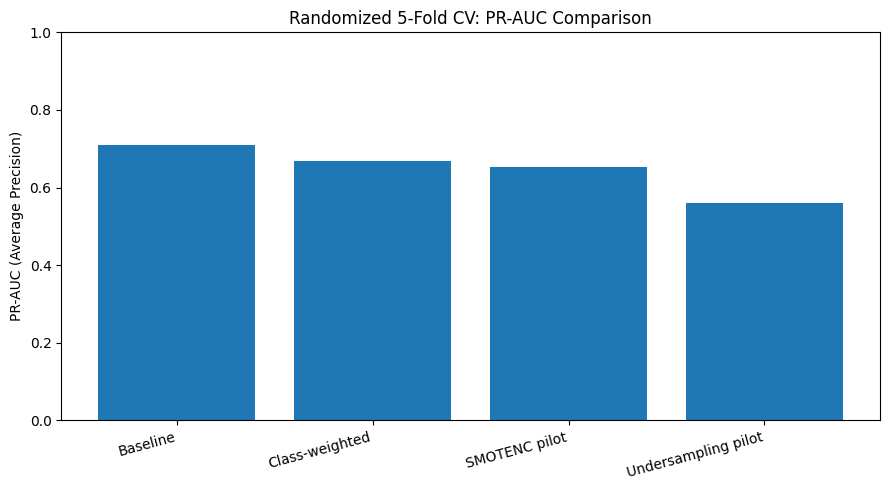

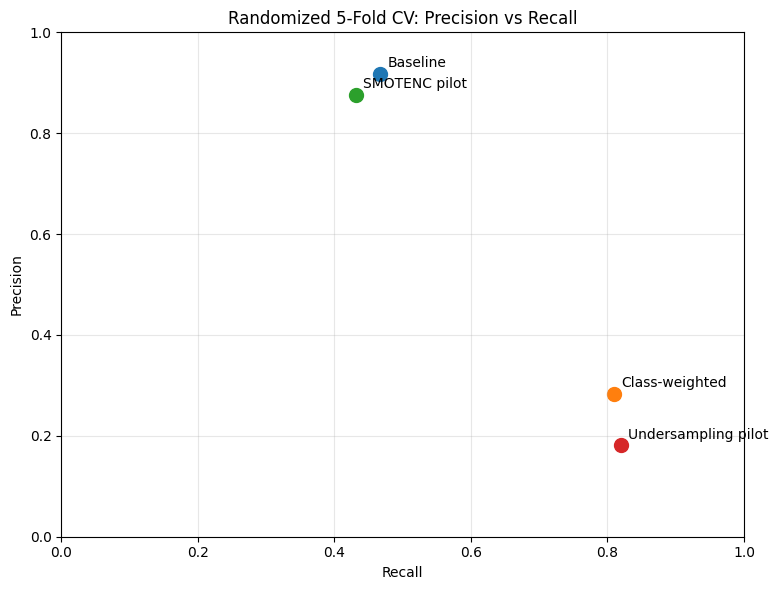

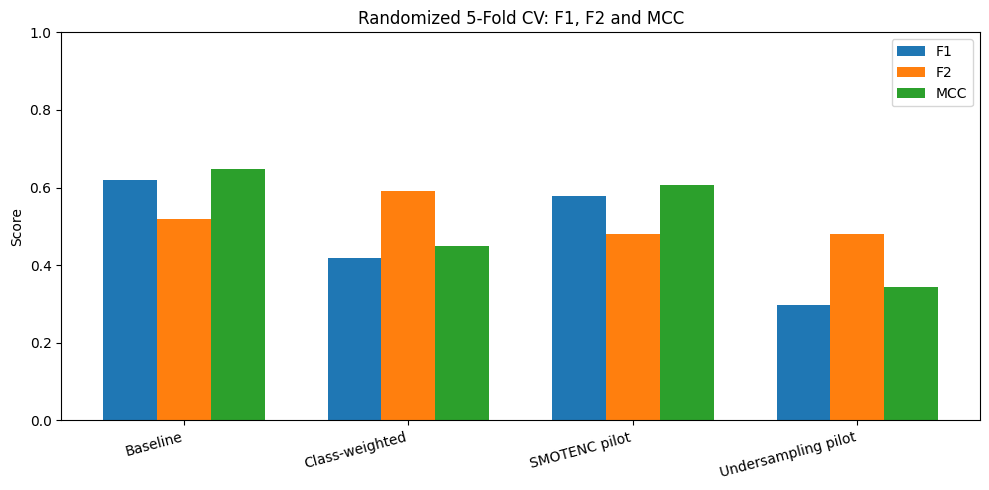

All three randomized comparison graphs saved in: /content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection


In [11]:

import os
import matplotlib.pyplot as plt
import numpy as np

# Ensure output folder exists
os.makedirs(RESULTS_DIR, exist_ok=True)

# Use shorter labels for graph readability
model_labels = [
    "Baseline",
    "Class-weighted",
    "SMOTENC pilot",
    "Undersampling pilot"
]

plot_df = randomized_comparison.copy()
plot_df["Graph label"] = model_labels

# Graph 1: PR-AUC
plt.figure(figsize=(9, 5))
plt.bar(plot_df["Graph label"], plot_df["PR-AUC (Average Precision)"])
plt.ylabel("PR-AUC (Average Precision)")
plt.title("Randomized 5-Fold CV: PR-AUC Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "randomized_pr_auc_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# Graph 2: Precision vs Recall
plt.figure(figsize=(8, 6))
for _, row in plot_df.iterrows():
    plt.scatter(row["Recall"], row["Precision"], s=100)
    plt.annotate(
        row["Graph label"],
        (row["Recall"], row["Precision"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Randomized 5-Fold CV: Precision vs Recall")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "randomized_precision_recall_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# Graph 3: F1, F2, and MCC
metrics_to_plot = ["F1", "F2", "MCC"]
x = np.arange(len(plot_df))
width = 0.24

plt.figure(figsize=(10, 5))
for i, metric in enumerate(metrics_to_plot):
    plt.bar(
        x + (i - 1) * width,
        plot_df[metric],
        width,
        label=metric
    )

plt.xticks(x, plot_df["Graph label"], rotation=15, ha="right")
plt.ylabel("Score")
plt.title("Randomized 5-Fold CV: F1, F2 and MCC")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "randomized_f1_f2_mcc_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

print("All three randomized comparison graphs saved in:", RESULTS_DIR)


Buliding the combined comparison table

In [12]:

import os
import pandas as pd

# Load the saved chronological results
chronological_file = os.path.join(
    RESULTS_DIR, "fraud_model_results.csv"
)

chronological_df = pd.read_csv(chronological_file)

metrics = [
    "PR-AUC (Average Precision)",
    "Precision",
    "Recall",
    "F1",
    "F2",
    "MCC"
]

print("Chronological results found:")
display(chronological_df)

# Keep the chronological evaluation rows
if "Evaluation" in chronological_df.columns:
    chrono = chronological_df[
        chronological_df["Evaluation"].astype(str).str.contains(
            "Chronological", case=False, na=False
        )
    ].copy()
else:
    chrono = chronological_df.copy()

# Assign clear method labels based on the saved model names
def identify_method(name):
    name = str(name).lower()

    if "undersampl" in name:
        return "Random undersampling"
    elif "smotenc" in name or "smote" in name:
        return "SMOTENC"
    elif "weight" in name or "balanced" in name:
        return "Class-weighted"
    elif "baseline" in name or "unweighted" in name:
        return "Baseline"
    return None

chrono["Method"] = chrono["Model"].apply(identify_method)
chrono = chrono[chrono["Method"].notna()].copy()
chrono["Evaluation type"] = "Chronological 70/30"

# Build randomized summary rows
randomized_rows = randomized_comparison.copy()
randomized_rows["Method"] = randomized_rows["Model"].apply(
    identify_method
)
randomized_rows["Evaluation type"] = "Randomized 5-fold CV"

# Standardize method labels
combined_results = pd.concat(
    [
        chrono[["Method", "Evaluation type"] + metrics],
        randomized_rows[["Method", "Evaluation type"] + metrics]
    ],
    ignore_index=True
)

# Save and display
combined_file = os.path.join(
    RESULTS_DIR, "combined_randomized_chronological_results.csv"
)

combined_results.to_csv(combined_file, index=False)

print("\nCOMBINED RESULTS")
display(
    combined_results.sort_values(
        ["Method", "Evaluation type"]
    ).round(4)
)

print("\nSaved combined table to:", combined_file)

# Check whether all expected method/evaluation combinations exist
print("\nNumber of rows by evaluation type:")
print(combined_results["Evaluation type"].value_counts())


Chronological results found:


,Evaluation,Model,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,Chronological 70/30,LightGBM baseline,0.523940,0.754934,0.343510,0.472172,0.385532,0.498481
1,Chronological 70/30,LightGBM class-weighted,0.527906,0.278389,0.661224,0.391815,0.518593,0.399169
2,Chronological 70/30,SMOTENC (50% training pilot),0.520928,0.752149,0.357224,0.484392,0.399139,0.507483
3,Chronological 70/30,Random Undersampling (50% training pilot),0.484363,0.198812,0.726531,0.312193,0.474586,0.341862



COMBINED RESULTS


,Method,Evaluation type,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
0,Baseline,Chronological 70/30,0.5239,0.7549,0.3435,0.4722,0.3855,0.4985
4,Baseline,Randomized 5-fold CV,0.7109,0.9171,0.4673,0.6190,0.5181,0.6467
1,Class-weighted,Chronological 70/30,0.5279,0.2784,0.6612,0.3918,0.5186,0.3992
5,Class-weighted,Randomized 5-fold CV,0.6696,0.2830,0.8097,0.4194,0.5901,0.4502
3,Random undersampling,Chronological 70/30,0.4844,0.1988,0.7265,0.3122,0.4746,0.3419
7,Random undersampling,Randomized 5-fold CV,0.5608,0.1809,0.8202,0.2964,0.4805,0.3448
2,SMOTENC,Chronological 70/30,0.5209,0.7521,0.3572,0.4844,0.3991,0.5075
6,SMOTENC,Randomized 5-fold CV,0.6527,0.8758,0.4320,0.5785,0.4807,0.6063



Saved combined table to: /content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection/combined_randomized_chronological_results.csv

Number of rows by evaluation type:
Evaluation type
Chronological 70/30     4
Randomized 5-fold CV    4
Name: count, dtype: int64


Creating the combined comparison graphs

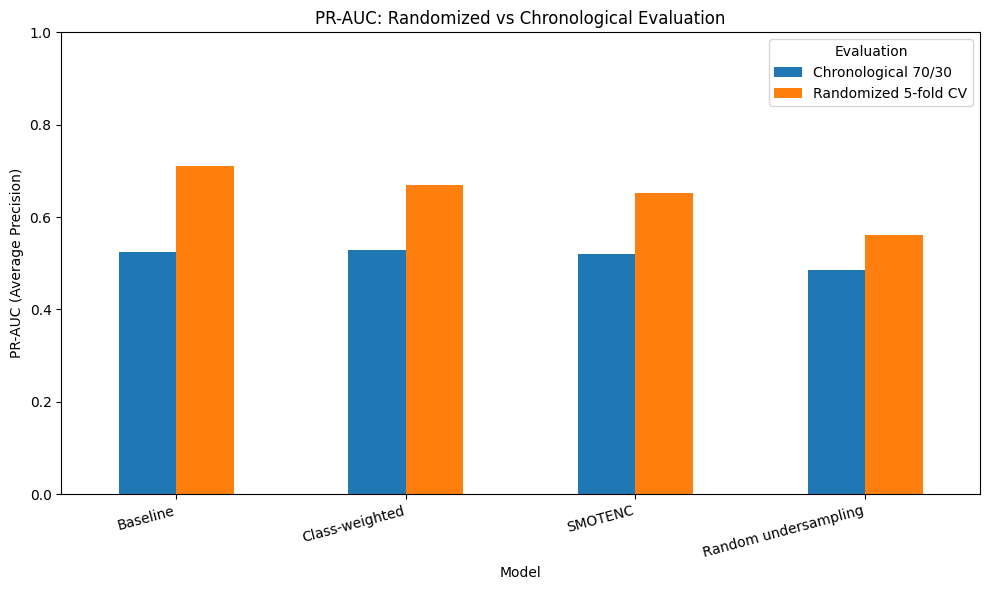

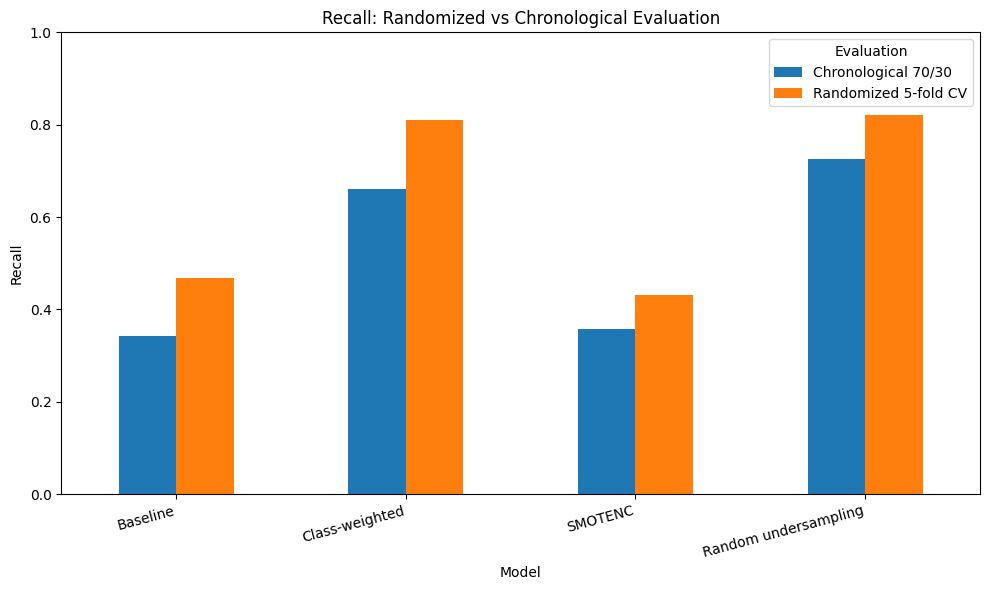

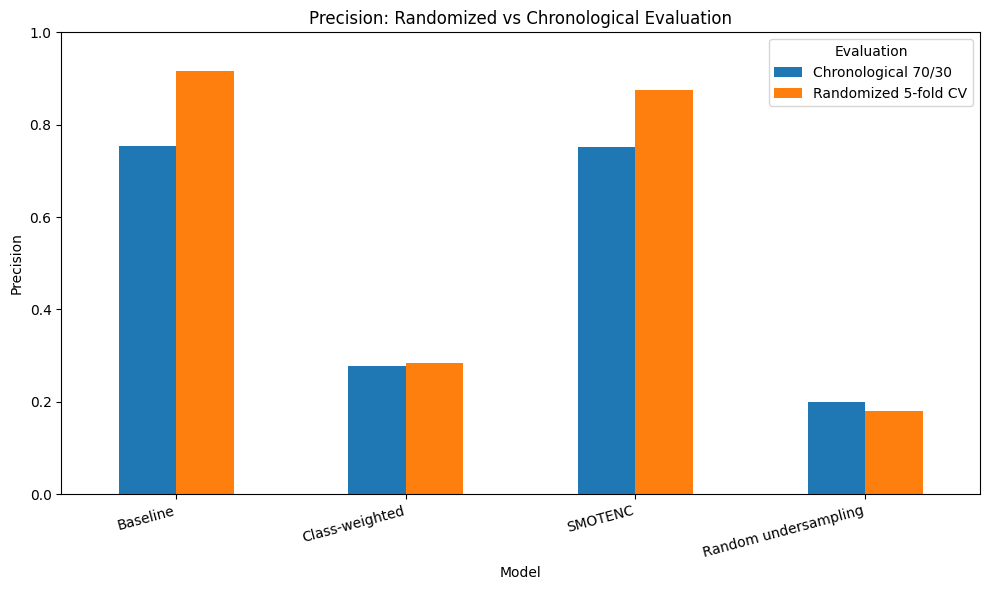

All three combined graphs saved in: /content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection


In [13]:

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure evaluation labels are in a consistent order
method_order = [
    "Baseline",
    "Class-weighted",
    "SMOTENC",
    "Random undersampling"
]

evaluation_order = [
    "Randomized 5-fold CV",
    "Chronological 70/30"
]

# Graph 1: PR-AUC by method and evaluation strategy
pivot_pr = combined_results.pivot(
    index="Method",
    columns="Evaluation type",
    values="PR-AUC (Average Precision)"
).reindex(method_order)

ax = pivot_pr.plot(kind="bar", figsize=(10, 6))
ax.set_title("PR-AUC: Randomized vs Chronological Evaluation")
ax.set_ylabel("PR-AUC (Average Precision)")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Evaluation")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "combined_pr_auc_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Graph 2: Recall by method and evaluation strategy
pivot_recall = combined_results.pivot(
    index="Method",
    columns="Evaluation type",
    values="Recall"
).reindex(method_order)

ax = pivot_recall.plot(kind="bar", figsize=(10, 6))
ax.set_title("Recall: Randomized vs Chronological Evaluation")
ax.set_ylabel("Recall")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Evaluation")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "combined_recall_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Graph 3: Precision by method and evaluation strategy
pivot_precision = combined_results.pivot(
    index="Method",
    columns="Evaluation type",
    values="Precision"
).reindex(method_order)

ax = pivot_precision.plot(kind="bar", figsize=(10, 6))
ax.set_title("Precision: Randomized vs Chronological Evaluation")
ax.set_ylabel("Precision")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Evaluation")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "combined_precision_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("All three combined graphs saved in:", RESULTS_DIR)


Generating a final results summary

In [14]:

# Find the highest-performing method for each metric
metrics = [
    "PR-AUC (Average Precision)",
    "Precision",
    "Recall",
    "F1",
    "F2",
    "MCC"
]

for evaluation in [
    "Randomized 5-fold CV",
    "Chronological 70/30"
]:
    subset = combined_results[
        combined_results["Evaluation type"] == evaluation
    ]

    print(f"\n{'=' * 55}")
    print(evaluation.upper())
    print("=" * 55)

    for metric in metrics:
        best_idx = subset[metric].idxmax()
        best_row = subset.loc[best_idx]

        print(
            f"{metric}: {best_row['Method']} "
            f"({best_row[metric]:.4f})"
        )

# Save a copy of the complete table for the report
summary_path = os.path.join(
    RESULTS_DIR,
    "final_model_results_for_report.csv"
)

combined_results.to_csv(summary_path, index=False)

print("\nFinal results table saved to:")
print(summary_path)



RANDOMIZED 5-FOLD CV
PR-AUC (Average Precision): Baseline (0.7109)
Precision: Baseline (0.9171)
Recall: Random undersampling (0.8202)
F1: Baseline (0.6190)
F2: Class-weighted (0.5901)
MCC: Baseline (0.6467)

CHRONOLOGICAL 70/30
PR-AUC (Average Precision): Class-weighted (0.5279)
Precision: Baseline (0.7549)
Recall: Random undersampling (0.7265)
F1: SMOTENC (0.4844)
F2: Class-weighted (0.5186)
MCC: SMOTENC (0.5075)

Final results table saved to:
/content/drive/MyDrive/M L project on creadit card fraud detection/IEEE-CIS-Fraud-Detection/final_model_results_for_report.csv


Audit your saved files

In [15]:

import os
import pandas as pd

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "M L project on creadit card fraud detection/"
    "IEEE-CIS-Fraud-Detection"
)

expected_files = [
    "fraud_model_results.csv",
    "randomized_baseline_fold_results.csv",
    "randomized_baseline_summary.csv",
    "randomized_weighted_fold_results.csv",
    "randomized_weighted_summary.csv",
    "randomized_smotenc_fold_results.csv",
    "randomized_smotenc_summary.csv",
    "randomized_undersampling_fold_results.csv",
    "randomized_undersampling_summary.csv",
    "randomized_model_comparison.csv",
    "combined_randomized_chronological_results.csv",
    "final_model_results_for_report.csv",
    "randomized_pr_auc_comparison.png",
    "randomized_precision_recall_comparison.png",
    "randomized_f1_f2_mcc_comparison.png",
    "combined_pr_auc_comparison.png",
    "combined_recall_comparison.png",
    "combined_precision_comparison.png"
]

audit_rows = []

for filename in expected_files:
    full_path = os.path.join(RESULTS_DIR, filename)
    audit_rows.append({
        "File": filename,
        "Exists": os.path.exists(full_path),
        "Size (KB)": (
            round(os.path.getsize(full_path) / 1024, 1)
            if os.path.exists(full_path) else None
        )
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

missing_files = audit_df.loc[~audit_df["Exists"], "File"].tolist()

if missing_files:
    print("\nFiles not found:")
    for filename in missing_files:
        print("-", filename)
else:
    print("\nAll expected result files and graphs are present.")


,File,Exists,Size (KB)
0,fraud_model_results.csv,True,0.7
1,randomized_baseline_fold_results.csv,True,0.6
2,randomized_baseline_summary.csv,True,0.2
3,randomized_weighted_fold_results.csv,True,0.6
4,randomized_weighted_summary.csv,True,0.2
5,randomized_smotenc_fold_results.csv,True,0.6
6,randomized_smotenc_summary.csv,True,0.2
7,randomized_undersampling_fold_results.csv,True,0.6
8,randomized_undersampling_summary.csv,True,0.2
9,randomized_model_comparison.csv,True,0.6



All expected result files and graphs are present.


Final research quality check

In [16]:

import os
import pandas as pd
import numpy as np

# Load the saved combined results
combined_file = os.path.join(
    RESULTS_DIR,
    "combined_randomized_chronological_results.csv"
)

final_results = pd.read_csv(combined_file)

# Basic checks
print("Rows in combined results:", len(final_results))
print("Expected rows:", 8)
print("\nRows per evaluation type:")
print(final_results["Evaluation type"].value_counts())

print("\nMissing values in result table:")
print(final_results.isna().sum())

print("\nMetric ranges:")
metric_cols = [
    "PR-AUC (Average Precision)",
    "Precision",
    "Recall",
    "F1",
    "F2",
    "MCC"
]

display(final_results[metric_cols].describe().round(4))

# Verify the expected method/evaluation combinations
expected_methods = {
    "Baseline",
    "Class-weighted",
    "SMOTENC",
    "Random undersampling"
}

expected_evaluations = {
    "Randomized 5-fold CV",
    "Chronological 70/30"
}

print(
    "\nAll four methods present:",
    set(final_results["Method"]) == expected_methods
)
print(
    "Both evaluation types present:",
    set(final_results["Evaluation type"]) == expected_evaluations
)
print(
    "Exactly one row per method/evaluation combination:",
    len(final_results) == 8
    and not final_results.duplicated(
        ["Method", "Evaluation type"]
    ).any()
)


Rows in combined results: 8
Expected rows: 8

Rows per evaluation type:
Evaluation type
Chronological 70/30     4
Randomized 5-fold CV    4
Name: count, dtype: int64

Missing values in result table:
Method                        0
Evaluation type               0
PR-AUC (Average Precision)    0
Precision                     0
Recall                        0
F1                            0
F2                            0
MCC                           0
dtype: int64

Metric ranges:


,PR-AUC (Average Precision),Precision,Recall,F1,F2,MCC
count,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000
mean,0.5814,0.5302,0.5772,0.4467,0.4809,0.4744
std,0.0839,0.3219,0.1995,0.1156,0.0661,0.1130
min,0.4844,0.1809,0.3435,0.2964,0.3855,0.3419
25%,0.5232,0.2585,0.4133,0.3719,0.4557,0.3856
50%,0.5443,0.5176,0.5643,0.4458,0.4806,0.4743
75%,0.6569,0.7852,0.7473,0.5079,0.5182,0.5322
max,0.7109,0.9171,0.8202,0.6190,0.5901,0.6467



All four methods present: True
Both evaluation types present: True
Exactly one row per method/evaluation combination: True
